# Middleware 실습: 도서관 상담 에이전트

**이 노트북에서 할 일**

1. 도서관 상담 에이전트가 쓸 도구 두 개와 기록 훅 네 개를 만듭니다.
2. 개인정보 가리기·호출 한도·감사 기록 미들웨어를 한 에이전트에 함께 등록해 대출 연장을 요청합니다(실행 1).
3. 호출 한도만 1로 낮춰 같은 요청을 보내고 결과를 비교합니다(실행 2).

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 3번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

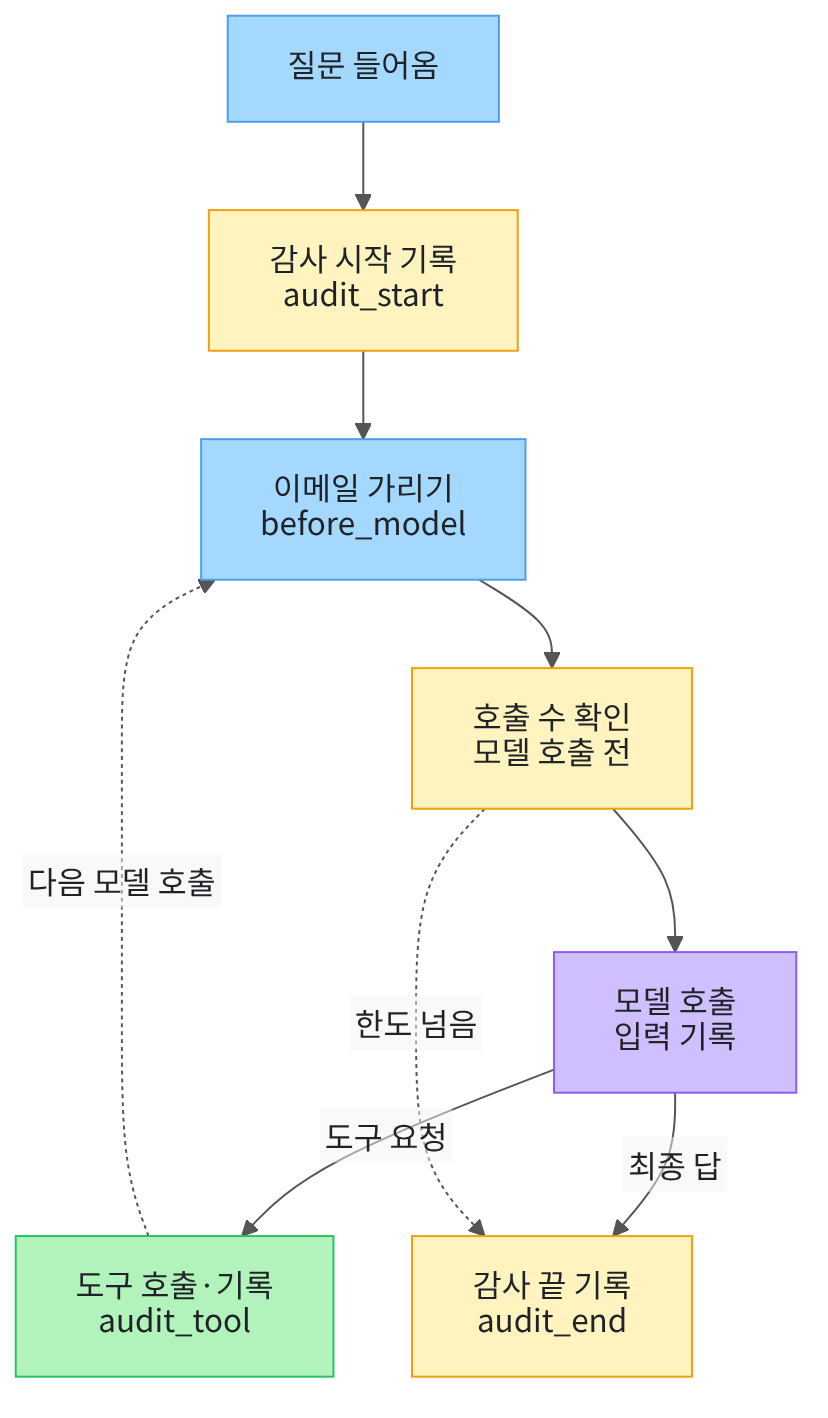

위에서 아래로 읽습니다. 질문이 들어오면 감사 시작, 이메일 가리기, 호출 수 확인을 거쳐 모델이 호출됩니다.
모델이 도구를 요청하면 도구 호출도 기록한 뒤 다시 모델 앞으로 돌아갑니다. 한도를 넘으면 감사 끝으로 갑니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 실습에서 쓰는 이름을 불러옵니다. 모두 01~08절에서 한 번씩 써 본 이름입니다.
새로 배우는 문법은 없습니다.

In [2]:
# 에이전트·미들웨어·훅·도구·모델을 만드는 도구를 불러옵니다
import json
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, ModelRequest, ModelResponse, Runtime, ToolCallRequest
from langchain.agents.middleware import ModelCallLimitMiddleware, PIIMiddleware
from langchain.agents.middleware import after_agent, before_agent, wrap_model_call, wrap_tool_call
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import ToolMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 실습 주제 — 도서관 상담 에이전트

도서관 이용자의 질문에 답하는 상담 에이전트를 만듭니다. 여기에 이 챕터에서 배운 미들웨어 세 가지를 붙입니다.
02절의 이메일 가리기, 04절의 호출 한도, 06절의 감사 기록입니다.

먼저 에이전트가 쓸 도구를 만듭니다. 첫 번째 도구는 01절에서 쓴 운영 시간 도구입니다.

In [5]:
# 자료실 운영 시간을 알려 주는 도구를 만듭니다
@tool
def lookup_hours(day: str) -> str:
    """자료실 운영 시간을 조회합니다. day에는 "평일" 또는 "토요일"을 넣습니다."""
    if day == "평일":
        return "평일 09:00~20:00"
    return "토요일 10:00~17:00"


print("도구 이름:", lookup_hours.name)

도구 이름: lookup_hours


**결과 읽기** — 도구 이름 `lookup_hours`가 출력됩니다.

두 번째 도구는 대출 기간을 연장합니다. 실습용이므로 실제 도서관 시스템에 연결하지 않고 안내 문장만 만듭니다.

In [6]:
# 책 제목을 받아 대출 연장 안내를 돌려주는 도구를 만듭니다
@tool
def renew_loan(book_title: str) -> str:
    """빌린 책의 대출 기간을 7일 연장합니다. book_title에는 책 제목을 넣습니다."""
    return book_title + " 대출을 7일 연장했습니다."


print("도구 이름:", renew_loan.name)

도구 이름: renew_loan


**결과 읽기** — 도구 이름 `renew_loan`이 출력됩니다. 모델은 질문을 보고 두 도구 중 필요한 것을 고릅니다.

## 3. 기록 훅 만들기

실행 결과를 확인하려면 기록이 필요합니다. 감사 사건을 담을 목록과, 모델이 받은 첫 메시지를 담을 목록을 만듭니다.

In [7]:
# 감사 사건과 모델 입력을 담을 빈 목록을 만듭니다
events = []
model_inputs = []
print("감사 사건 수:", len(events))
print("모델 입력 기록 수:", len(model_inputs))

감사 사건 수: 0
모델 입력 기록 수: 0


**결과 읽기** — 두 목록 모두 `0`개로 시작합니다.

06절처럼 에이전트가 시작할 때 사건을 남기는 훅을 만듭니다. 질문 원문 대신 글자 수만 적습니다.

In [8]:
# 에이전트가 시작할 때 질문의 글자 수를 기록하는 훅
@before_agent
def audit_start(state: AgentState, runtime: Runtime) -> None:
    first_text = state["messages"][0].text
    events.append({"event": "agent_start", "input_chars": len(first_text)})

출력은 없습니다. 두 번째 감사 훅은 도구 호출을 감싸고 도구 이름을 기록합니다.

In [9]:
# 도구를 부를 때마다 도구 이름을 기록하는 훅
@wrap_tool_call
def audit_tool(request: ToolCallRequest, handler: Callable) -> ToolMessage:
    events.append({"event": "tool_call", "tool": request.tool_call["name"]})
    return handler(request)

출력은 없습니다. 세 번째 감사 훅은 에이전트가 끝날 때 대화 기록의 메시지 수를 남깁니다.

In [10]:
# 에이전트가 끝날 때 메시지 수를 기록하는 훅
@after_agent
def audit_end(state: AgentState, runtime: Runtime) -> None:
    events.append({"event": "agent_end", "messages": len(state["messages"])})

출력은 없습니다. 마지막 훅은 모델을 부를 때마다 모델이 받은 첫 메시지를 적습니다.
이 목록의 길이가 모델 호출 횟수이고, 첫 항목에서 이메일이 가려졌는지 볼 수 있습니다.

In [11]:
# 모델을 부를 때마다 모델이 받은 첫 메시지를 적는 훅
@wrap_model_call
def record_model_call(request: ModelRequest, handler: Callable) -> ModelResponse:
    model_inputs.append(request.messages[0].text)
    return handler(request)

출력은 없습니다.

## 4. 미들웨어 모으기

02절에서 쓴 이메일 마스킹 미들웨어를 만듭니다. 모델에 보내는 입력에만 적용합니다.

In [12]:
# 이메일을 별표로 가리는 미들웨어를 만듭니다
email_mask = PIIMiddleware("email", strategy="mask", apply_to_input=True)
print("미들웨어 이름:", email_mask.name)

미들웨어 이름: PIIMiddleware[email]


**결과 읽기** — 미들웨어 이름에 `email`이 들어 있습니다.

04절의 호출 한도 미들웨어를 만듭니다. 대출 연장은 도구를 쓰므로 모델을 최소 두 번 부릅니다(04절).
그래서 한도를 넉넉하게 4로 둡니다.
그다음 미들웨어 여섯 개를 한 목록에 담아 에이전트를 만듭니다. 목록의 주석은 각 미들웨어를 배운 절입니다.

In [13]:
# 호출 한도 4의 미들웨어를 만들고, 미들웨어 여섯 개로 에이전트를 만듭니다
limit_four = ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")
tools = [lookup_hours, renew_loan]
middleware = [
    email_mask,  # 02절 이메일 가리기
    limit_four,  # 04절 호출 한도
    audit_start,  # 06절 감사 기록
    audit_tool,
    audit_end,
    record_model_call,  # 01·02절 모델 입력 기록
]
agent = create_agent(model, tools=tools, middleware=middleware)
print("등록한 도구 수:", len(tools))
print("등록한 미들웨어 수:", len(middleware))

등록한 도구 수: 2
등록한 미들웨어 수: 6


**결과 읽기** — 도구 `2`개와 미들웨어 `6`개를 등록했습니다.
02절에서 본 것처럼 이메일 가리기는 before_model 자리에서 실행됩니다.
그래서 07절 규칙대로 감싸기형 기록 훅은 가려진 글을 받습니다.

## 5. 실행 1 — 이메일이 든 대출 연장 요청

이용자가 이메일과 함께 대출 연장을 요청합니다. 실행 전에 예상해 봅니다.
모델은 `renew_loan` 도구를 고르고, 모델이 받은 글에서는 이메일이 가려져 있을 것입니다.

In [14]:
# 이메일이 든 대출 연장 요청을 보냅니다
request_text = "제 이메일은 learner@example.com 입니다. 『파이썬 첫걸음』 대출을 연장해 주세요."
result = agent.invoke({"messages": [{"role": "user", "content": request_text}]})
last_message = result["messages"][-1]
print("최종 답:", last_message.text)

최종 답: 『파이썬 첫걸음』 대출을 7일 연장했습니다.


**결과 읽기** — 최종 답에 `7일 연장`이 들어 있습니다. 모델이 도구 결과를 읽고 답했습니다.
답 문장은 실행할 때마다 달라질 수 있습니다.

대화 기록을 종류별로 출력해 어떤 도구가 쓰였는지 봅니다.

In [15]:
# 대화 기록에 쌓인 메시지를 종류별로 출력합니다
for message in result["messages"]:
    print(message.type, "|", message.text)

human | 제 이메일은 learner@****.com 입니다. 『파이썬 첫걸음』 대출을 연장해 주세요.
ai | 
tool | 파이썬 첫걸음 대출을 7일 연장했습니다.
ai | 『파이썬 첫걸음』 대출을 7일 연장했습니다.


**결과 읽기** — 두 번째 줄의 ai 메시지는 글자가 비어 있습니다. 이 메시지가 도구를 요청했습니다.
도구 결과인 tool 메시지에 `대출을 7일 연장했습니다`가 있습니다. 첫 human 메시지의 이메일도 가려진 채 저장됐습니다.

이제 기록 훅이 남긴 모델 입력을 확인합니다.

In [16]:
# 모델 호출 횟수와 모델이 받은 첫 메시지를 확인합니다
print("모델 호출 횟수:", len(model_inputs))
print("모델이 받은 글:", model_inputs[0])
email_sent = "learner@example.com" in model_inputs[0]
print("모델 입력에 이메일 원문이 있나:", email_sent)
assert not email_sent

모델 호출 횟수: 2
모델이 받은 글: 제 이메일은 learner@****.com 입니다. 『파이썬 첫걸음』 대출을 연장해 주세요.
모델 입력에 이메일 원문이 있나: False


**결과 읽기** — 모델 호출 횟수는 `2`입니다. 모델이 받은 글에는 `learner@****.com`이 보이고, 원문 확인 결과는 `False`입니다.
호출 2번은 한도 4 안이므로 호출 한도 미들웨어는 실행을 멈추지 않았습니다.

마지막으로 감사 기록을 확인합니다.

In [17]:
# 감사 사건을 출력하고, 기록에 이메일 원문이 없는지 확인합니다
for event in events:
    print(event)
saved_text = json.dumps(events, ensure_ascii=False)
print("감사 기록에 이메일 원문이 있나:", "learner@example.com" in saved_text)
assert events[0]["event"] == "agent_start"
assert events[-1]["event"] == "agent_end"

{'event': 'agent_start', 'input_chars': 54}
{'event': 'tool_call', 'tool': 'renew_loan'}
{'event': 'agent_end', 'messages': 4}
감사 기록에 이메일 원문이 있나: False


**결과 읽기** — 사건이 `agent_start`, `tool_call`, `agent_end` 순서로 남았습니다. 도구 사건의 이름은 `renew_loan`입니다.
모델이 두 도구 중 대출 연장 도구를 골랐다는 뜻입니다. 운영 시간 도구는 이번 질문에 쓰이지 않았습니다.

감사 기록에 이메일 원문이 있는지 확인한 결과도 `False`입니다. 세 미들웨어가 한 에이전트에서 각자 제 역할을 했습니다.

## 6. 실행 2 — 호출 한도를 1로 낮추기

같은 요청을 호출 한도 1로 보냅니다. 나머지 미들웨어와 도구는 그대로입니다. 실행 전에 예상해 봅니다.
첫 호출에서 도구는 실행되지만, 도구 결과를 읽을 두 번째 모델 호출은 한도에 걸릴 것입니다.

In [18]:
# 기록을 비우고, 호출 한도만 1로 바꾼 에이전트로 같은 요청을 보냅니다
events.clear()
model_inputs.clear()
limit_one = ModelCallLimitMiddleware(run_limit=1, exit_behavior="end")
middleware_one = [email_mask, limit_one, audit_start, audit_tool, audit_end, record_model_call]
agent_one = create_agent(model, tools=tools, middleware=middleware_one)
result_one = agent_one.invoke({"messages": [{"role": "user", "content": request_text}]})
print("최종 메시지:", result_one["messages"][-1].text)

최종 메시지: Model call limits exceeded: run limit (1/1)


**결과 읽기** — 최종 메시지가 `Model call limits exceeded`로 시작하는 안내입니다. 04절에서 본 것과 같은 멈춤입니다.

In [19]:
# 실행 2의 대화 기록, 모델 호출 횟수, 감사 사건을 확인합니다
for message in result_one["messages"]:
    print(message.type, "|", message.text)
print("모델 호출 횟수:", len(model_inputs))
for event in events:
    print(event)
assert len(model_inputs) == 1

human | 제 이메일은 learner@****.com 입니다. 『파이썬 첫걸음』 대출을 연장해 주세요.
ai | 
tool | 파이썬 첫걸음 대출을 7일 연장했습니다.
ai | Model call limits exceeded: run limit (1/1)
모델 호출 횟수: 1
{'event': 'agent_start', 'input_chars': 54}
{'event': 'tool_call', 'tool': 'renew_loan'}
{'event': 'agent_end', 'messages': 4}


**결과 읽기** — tool 메시지에 `대출을 7일 연장했습니다`가 있어 도구가 실행됐음을 알 수 있습니다.
모델 호출 횟수는 `1`입니다. 두 번째 호출은 기록 훅에 닿기 전에 멈췄습니다.
최종 답은 없었지만 감사 기록의 시작과 끝 사건은 그대로 남았습니다.

## 정리

- 이메일 가리기, 호출 한도, 감사 기록 미들웨어를 한 목록에 담아 한 에이전트에 함께 등록했습니다.
- 실행 1에서 모델 입력과 감사 기록 모두 이메일 원문이 없었고, 호출 2번은 한도 4 안이었습니다.
- 실행 2에서 한도 값 하나만 1로 바꾸자 도구 실행 뒤 두 번째 모델 호출에서 멈췄습니다. 감사 끝 사건은 남았습니다.